# ACF, timescale analysis

## A. Analytical toy model, no noise

Trying to extract parameters from toy model
$$
\hat{C}_1(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from vac_metad.acf_toy import toy_model_acf
from vac_metad.acf_analysis import (
    acf_input,
    acf_timescales,
    slow_mode_analysis,
    fit_multi_exponential,
)

dt = 1.0  # ps
toy = toy_model_acf(np.arange(0, 20_000, dt))
acf = acf_input(toy, dt)  # no noise info: sigma = None

ts = acf_timescales(acf)
sm = slow_mode_analysis(acf, split_window=(300.0, 1200.0))
print(ts)
print(sm)
for n in (2, 3, 4):
    m = fit_multi_exponential(acf, n, sum_to_one=True)
    print(n, m.coeffs.round(3), m.timescales.round(1), f"cond={m.cond:.2g}")

tau_0: 21.64, tau_int_sokal: 1260.94, tau_int_window: 6305.00, tau_int: 1303.80, t1: 1850.00, a1: 0.70, t1_err: 0.00, a1_err: 0.00, purity: 0.70, t_min: 1999.90, t_max: 19999.00
a1: 0.70, a1_tail: 0.70, t1: 1850.00, tau_R: 28.98, R_window: 300.00, tau_R_resolved: 1.00, gap: 63.84, log_gap: 4.16, signal_ratio: 2.34, tau_int: 1303.80, tau_int_sokal: 1260.94, tau_int_identity: 1304.33, identity_error: 0.53, slow_share: 0.99, t_min: 1999.90, t_max: 19999.00, t: ndarray(20000,), R: ndarray(20000,)
2 [0.704 0.296] [1840.1   24.4] cond=7.6
3 [0.701 0.183 0.116] [1848.6   44.5    2.6] cond=6.3e+02
4 [0.7 0.1 0.1 0.1] [1850.   60.   26.    2.] cond=2.4e+05


In [ ]:
def fit_window(acf, t_min=None, t_max=None, k_sigma=3.0, t_min_frac=0.1):
    """Return (t_min, t_max) for the slow-tail fit.

    t_max : given, or the last lag before C_hat first drops below
            k_sigma * sigma (searching from lag 1), or the last lag if
            acf.sigma is None.
    t_min : given, or t_min_frac * t_max.
    """
    t, ct = acf.t, acf.ct
    if t_max is None:
        if acf.sigma is None:
            t_max = t[-1]
        else:
            low = np.flatnonzero(ct[1:] < k_sigma * acf.sigma[1:])
            t_max = t[low[0]] if low.size else t[-1]  # low[0]+1 is the first bad lag
    if t_min is None:
        t_min = t_min_frac * t_max
    if t_min >= t_max:
        raise ValueError(f"empty fit window: t_min={t_min} >= t_max={t_max}")
    return float(t_min), float(t_max)

In [ ]:
def fit_slow_exponential(
    acf,
    t_min=None,
    t_max=None,
    method="nonlinear",
    unit_amplitude=False,
    k_sigma=3.0,
    t_min_frac=0.1,
):
    """Fit C(t) ~ a_1 exp(-t / t_1) on [t_min, t_max].

    Parameters
    ----------
    acf : DataClass from acf_input
    t_min, t_max, k_sigma, t_min_frac : fit window, see fit_window
    method : 'nonlinear' (default) fits C itself, weighted by 1/sigma^2.
             'log' fits ln C by a straight line, weighted by C^2/sigma^2
             (the consistent weight for ln C).  Points with C <= 0 are
             dropped, which biases it upward in a noisy tail.
    unit_amplitude : force a_1 = 1 (the fit then goes through C(0) = 1)

    Returns
    -------
    DataClass with a1, t1, a1_err, t1_err, t_min, t_max, num_points.
    The errors assume independent noise per lag and are too small for real
    ACFs; use spread_over_draws for honest errors.
    """
    t_min, t_max = fit_window(acf, t_min, t_max, k_sigma, t_min_frac)
    sel = (acf.t >= t_min) & (acf.t <= t_max)
    t, c = acf.t[sel], acf.ct[sel]
    s = None if acf.sigma is None else acf.sigma[sel]

    # log-linear fit (also the starting guess for the nonlinear fit)
    pos = c > 0.0
    if pos.sum() < 2:
        raise ValueError("fewer than 2 positive C values in the fit window")
    s_log = None if s is None else s[pos] / c[pos]
    slope, icpt, cov = weighted_linear_fit(
        t[pos], np.log(c[pos]), s_log, through_origin=unit_amplitude
    )
    k, a = -slope, np.exp(icpt)
    k_err, a_err = np.sqrt(cov[0, 0]), a * np.sqrt(cov[1, 1])

    if method == "nonlinear":
        if unit_amplitude:
            f = lambda t, k: np.exp(-k * t)
            p0 = [k]
        else:
            f = lambda t, a, k: a * np.exp(-k * t)
            p0 = [a, k]
        p, pcov = curve_fit(f, t, c, p0=p0, sigma=s, absolute_sigma=s is not None)
        if unit_amplitude:
            k, k_err = p[0], np.sqrt(pcov[0, 0])
        else:
            (a, k), (a_err, k_err) = p, np.sqrt(np.diag(pcov))
    elif method != "log":
        raise ValueError("method must be 'nonlinear' or 'log'")

    return DataClass(
        a1=a,
        t1=1.0 / k,
        a1_err=a_err,
        t1_err=k_err / k**2,
        t_min=t_min,
        t_max=t_max,
        num_points=int(sel.sum()),
    )

In [ ]:
def acf_timescales(acf, c_window=5.0, **fit_kwargs):
    """The main timescales of an ACF.

    Parameters
    ----------
    acf : DataClass from acf_input
    c_window : Sokal window constant for tau_int_sokal
    fit_kwargs : passed to fit_slow_exponential (t_min, t_max, method, ...)

    Returns
    -------
    DataClass with
        tau_0 : one-frame chord -dt / ln C(dt); approximates -1/C'(0) only
            for dt much shorter than the fastest mode
        tau_int_sokal : Sokal-windowed integral of C (as in acf.py)
        tau_int_window : the Sokal window, in time units
        tau_int : tail-corrected integral of C (preferred)
        t1 : slowest timescale in u (= tau_exp), from the slow-tail fit
        a1 : slow-mode weight (fit intercept)
        a1_err, t1_err : single-fit errors (optimistic)
        purity : tau_int / t1, an upper bound on a1 (equal to it when the
            fast modes are negligibly short)
        t_min, t_max : slow-tail fit window
    """
    fit = fit_slow_exponential(acf, **fit_kwargs)
    tau_sokal, t_win = sokal_tau_int(acf, c_window)
    tau_int = tail_corrected_tau_int(acf, fit.a1, fit.t1, fit.t_max)
    c1 = acf.ct[1]
    tau_0 = -acf.frametime / np.log(c1) if 0.0 < c1 < 1.0 else np.nan
    return DataClass(
        tau_0=tau_0,
        tau_int_sokal=tau_sokal,
        tau_int_window=t_win,
        tau_int=tau_int,
        t1=fit.t1,
        a1=fit.a1,
        t1_err=fit.t1_err,
        a1_err=fit.a1_err,
        purity=tau_int / fit.t1,
        t_min=fit.t_min,
        t_max=fit.t_max,
    )

### A.2 Estimate of $a_1$

Estimates: t1 = 1850.000 ps, a1 = 0.7000


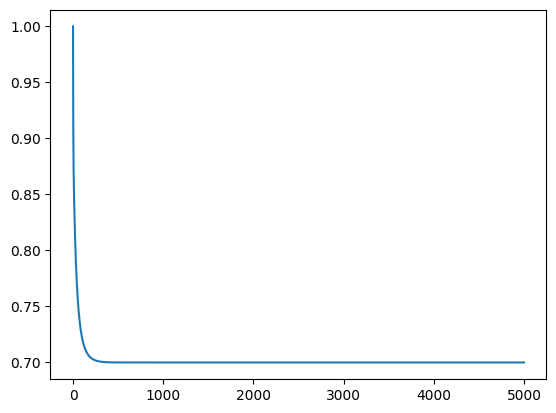

In [12]:
t1_est = np.mean(t1_local[1000:])
a1_local = np.exp(np.log(acf.ct) + taus / t1_est)
a1_est = np.mean(a1_local[1000:])
print(f"Estimates: t1 = {t1_est:.3f} ps, a1 = {a1_est:.4f}")
plt.plot(a1_local)

np.float64(1849.999978885504)